# 4.2 SciPy и двухтемпературная модель

# 4.2 SciPy 与双温模型

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (7, 4.3), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.2})
from scipy.integrate import solve_ivp
from scipy.special import erf

Matplotlib is building the font cache; this may take a moment.


## Охлаждение с `solve_ivp`
Используем те же параметры. `t_eval` задаёт точки вывода, а внутренние шаги RK45 выбирает сам решатель.

## 使用 `solve_ivp` 求解冷却过程
沿用相同参数。`t_eval` 指定输出时刻，RK45 的内部步长仍由求解器自适应选取。

In [2]:
k, T_inf, T0 = 0.2, 20.0, 100.0

def rhs_cooling(t, T):
    return -k * (T - T_inf)

t_eval = np.linspace(0, 20, 201)
sol_cooling = solve_ivp(
    rhs_cooling, (0, 20), [T0],
    t_eval=t_eval, method="RK45",
    rtol=1e-7, atol=1e-9)
T_exact = T_inf + (T0-T_inf)*np.exp(-k*t_eval)
cooling_error = np.max(abs(sol_cooling.y[0]-T_exact))
print("Успех / 成功:", sol_cooling.success)
print(f"Максимальная ошибка / 最大误差: {cooling_error:.3e} K")

Успех / 成功: True
Максимальная ошибка / 最大误差: 2.496e-06 K


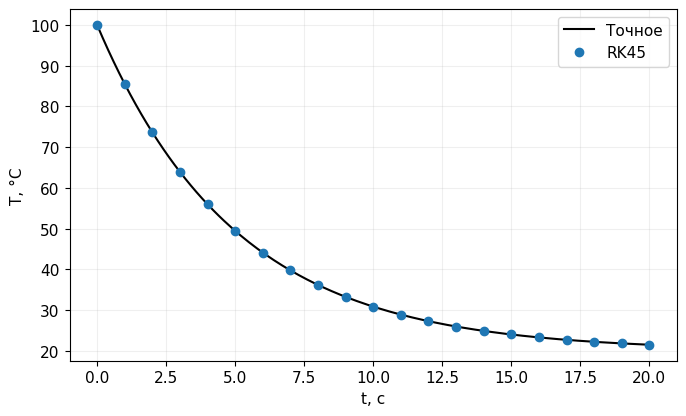

In [3]:
fig, ax = plt.subplots()
ax.plot(t_eval, T_exact, color="black", label="Точное")
ax.plot(sol_cooling.t[::10], sol_cooling.y[0, ::10], "o", label="RK45")
ax.set(xlabel="t, с", ylabel="T, °C")
ax.legend(); fig.tight_layout(); plt.show()

## Внутренние шаги
Без `t_eval` массив `sol.t` содержит узлы, выбранные решателем. Это другой набор точек вывода, а не другой физический закон.

## 内部时间步
不设置 `t_eval` 时，`sol.t` 返回求解器自行选取的节点。输出网格改变，物理模型不变。

In [4]:
sol_internal = solve_ivp(
    rhs_cooling, (0, 20), [T0],
    method="RK45", rtol=1e-7, atol=1e-9)
print("Узлы вывода / 输出节点:", len(sol_cooling.t))
print("Внутренние узлы / 内部节点:", len(sol_internal.t))
print("Первые шаги / 前几个步长:", np.diff(sol_internal.t)[:5])

Узлы вывода / 输出节点: 201
Внутренние узлы / 内部节点: 26
Первые шаги / 前几个步长: [0.02286571 0.2286571  0.77548424 0.770232   0.77560456]


## Электроны и решётка
$$C_e\dot T_e=-G(T_e-T_l)+S(t),\qquad C_l\dot T_l=G(T_e-T_l).$$
$T_e(0)=T_l(0)=300$ K. Берём учебные постоянные $C_e=1$, $C_l=5$, $G=0.8$.
Время, теплоёмкости и источник заданы в согласованных условных единицах; это не параметры конкретного материала. Теплообмена с внешней средой нет.

## 电子与晶格
初始温度均为 300 K，使用教学参数 $C_e=1$、$C_l=5$、$G=0.8$。时间、热容和热源采用相容的约定单位，不代表具体材料。本例没有与外界的热交换。

In [5]:
Ce, Cl, G = 1.0, 5.0, 0.8

def source(t):
    return 200.0 * np.exp(-(t - 1.0)**2 / 0.1)

def rhs_ttm(t, y):
    Te, Tl = y
    q = G * (Te - Tl)
    return [(-q + source(t)) / Ce, q / Cl]

## Импульсный нагрев
`max_step=0.02` ограничивает шаг, чтобы разрешить короткий импульс около t=1. Проверяем результат повторным расчётом с меньшим шагом и допусками.

## 脉冲加热
用 `max_step=0.02` 限制内部步长，以分辨 t=1 附近的短脉冲。再用更小步长及容差进行复算。

In [6]:
times = np.linspace(0, 10, 501)
sol_ttm = solve_ivp(
    rhs_ttm, (0, 10), [300., 300.],
    t_eval=times, method="RK45",
    rtol=1e-7, atol=1e-9, max_step=0.02)
Te, Tl = sol_ttm.y
print("Успех / 成功:", sol_ttm.success)
print(f"Te(10)={Te[-1]:.6f} K; Tl(10)={Tl[-1]:.6f} K")
print(f"Максимум Te на сетке / 网格上的 Te 峰值: {Te.max():.3f} K")

Успех / 成功: True
Te(10)=318.700141 K; Tl(10)=318.679850 K
Максимум Te на сетке / 网格上的 Te 峰值: 379.849 K


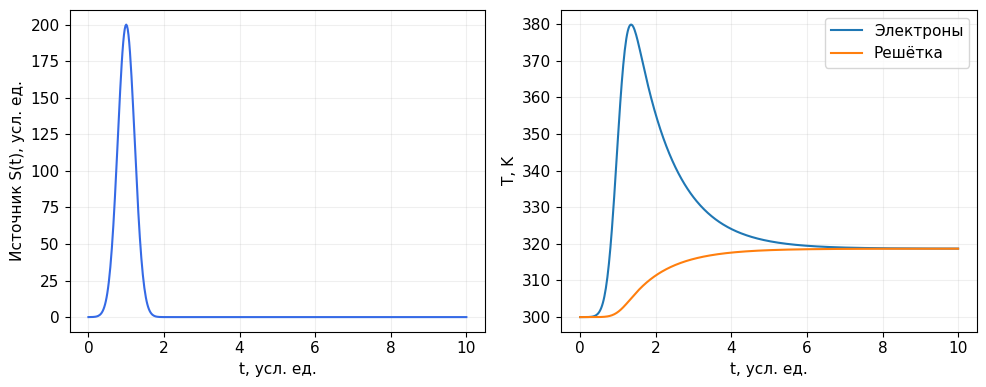

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(times, source(times), color="#356AE6")
axes[0].set(xlabel="t, усл. ед.", ylabel="Источник S(t), усл. ед.")
axes[1].plot(times, Te, label="Электроны")
axes[1].plot(times, Tl, label="Решётка")
axes[1].set(xlabel="t, усл. ед.", ylabel="T, K")
axes[1].legend(); fig.tight_layout(); plt.show()

## Баланс энергии
Складывая уравнения, получаем $d(C_eT_e+C_lT_l)/dt=S(t)$.
Прирост энергии должен совпасть с интегралом источника. Для гауссова импульса вычислим интеграл через `erf`, независимо от решателя ОДУ.

## 能量平衡
两式相加得到 $d(C_eT_e+C_lT_l)/dt=S(t)$。能量增量应等于热源积分。高斯脉冲的积分可用 `erf` 计算，作为独立校验。

In [8]:
sigma = np.sqrt(0.1)
energy_in = 200*sigma*np.sqrt(np.pi)/2 * (
    erf((times-1)/sigma) - erf(-1/sigma))
energy_gain = Ce*(Te-300) + Cl*(Tl-300)
energy_error = np.max(abs(energy_gain-energy_in))
T_equilibrium = 300 + energy_in[-1]/(Ce+Cl)
print(f"Ошибка баланса / 能量平衡误差: {energy_error:.3e}")
print(f"Предельная температура / 最终平衡温度: {T_equilibrium:.6f} K")
sol_fine = solve_ivp(
    rhs_ttm, (0, 10), [300., 300.], t_eval=times,
    rtol=1e-9, atol=1e-11, max_step=0.01)
ttm_difference = np.max(abs(sol_ttm.y-sol_fine.y))
print(f"Разница повторных расчётов / 复算差异: {ttm_difference:.3e} K")

Ошибка баланса / 能量平衡误差: 1.186e-09
Предельная температура / 最终平衡温度: 318.683232 K
Разница повторных расчётов / 复算差异: 1.191e-09 K


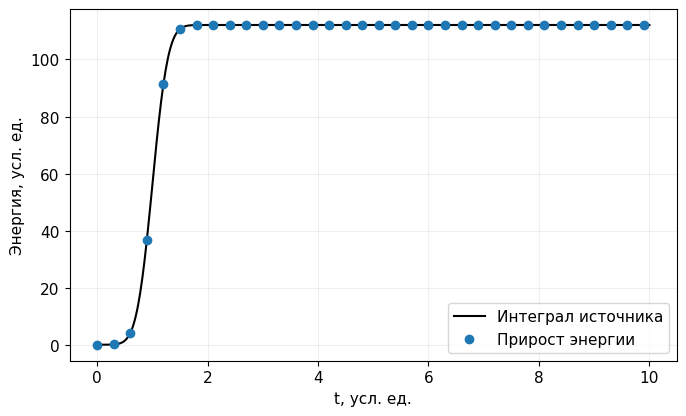

In [9]:
fig, ax = plt.subplots()
ax.plot(times, energy_in, color="black", label="Интеграл источника")
ax.plot(times[::15], energy_gain[::15], "o", label="Прирост энергии")
ax.set(xlabel="t, усл. ед.", ylabel="Энергия, усл. ед.")
ax.legend(); fig.tight_layout(); plt.show()